# Homework07

Exercises to practice pandas, data analysis and regression

## Goals

- Understand the effects of pre-processing data
- Get familiar with the ML flow: encode -> normalize -> train -> evaluate
- Understand the difference between regression and classification tasks
- Build intuition for different regression models

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor

from data_utils import object_from_json_url
from data_utils import regression_error

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/DM-GY-9103-2024F-H/WK02).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [3]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

#### Nested data

This is that *nested* dataset from Week 02.

# 🤔

Let's load it into a `DataFrame` to see what happens.

In [4]:
# Read into DataFrame
ansur_df = pd.DataFrame.from_records(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear,foot,hand,head
0,18,F,66,135,1699,1645,"{'breadth': 30, 'length': 61, 'protrusion': 20}","{'breadth': 97, 'length': 243}","{'breadth': 78, 'length': 182, 'palm': 108}","{'height': 243, 'circumference': 557}"
1,30,M,68,207,1749,1715,"{'breadth': 35, 'length': 63, 'protrusion': 17}","{'breadth': 100, 'length': 252}","{'breadth': 87, 'length': 184, 'palm': 114}","{'height': 238, 'circumference': 560}"
2,27,M,67,121,1684,1657,"{'breadth': 36, 'length': 59, 'protrusion': 24}","{'breadth': 92, 'length': 251}","{'breadth': 84, 'length': 180, 'palm': 103}","{'height': 239, 'circumference': 516}"
3,20,M,73,185,1878,1828,"{'breadth': 36, 'length': 60, 'protrusion': 21}","{'breadth': 104, 'length': 280}","{'breadth': 95, 'length': 201, 'palm': 124}","{'height': 270, 'circumference': 582}"
4,33,M,76,150,1977,1883,"{'breadth': 39, 'length': 65, 'protrusion': 27}","{'breadth': 101, 'length': 271}","{'breadth': 90, 'length': 194, 'palm': 113}","{'height': 254, 'circumference': 559}"



# 😓🙄

That didn't work too well. We ended up with objects in our columns.

Luckily, our `DataFrame` library has a function called [`json_normalize()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.json_normalize.html) that can help.

In [5]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


In [ ]:
** i think it would be helpful to have the units printed... let me see mwehehhe

In [ ]:
# units for each column as context
units = {
    "age": "years",
    "gender": "category (F / M)",
    "height": "inches",
    "weight": "pounds",
}

for col in ansur_df.columns:
    if col in units:
        print(col, "->", units[col])
    else:
        print(col, "-> mm")

age -> years
gender -> category (F / M)
height -> inches
weight -> pounds
span -> mm
stature -> mm
ear.breadth -> mm
ear.length -> mm
ear.protrusion -> mm
foot.breadth -> mm
foot.length -> mm
hand.breadth -> mm
hand.length -> mm
hand.palm -> mm
head.height -> mm
head.circumference -> mm


Much better. `DataFrames` are magic.

#### Data Exploration

Before we start creating models, let's do a little bit of data analysis and get a feeling for the shapes, distributions and relationships of our data.

1. Print `min`, `max` and `average` values for all of the features.
2. Print `covariance` tables for `age`, `ear.length` and `head.circumference`.
3. Plot `age`, `ear.length` and `head.circumference` versus the $1$ *feature* that is most correlated to each of them.

Don't forget to *encode* and *normalize* the data.

<StringArray>
['F', 'M']
Length: 2, dtype: str
[0 1]
age
	min: 17
	max: 58
	avg: 29.74535714285714
gender
	min: 0
	max: 1
	avg: 0.6726785714285715
height
	min: 56
	max: 94
	avg: 68.24732142857142
weight
	min: 0
	max: 321
	avg: 174.55839285714285
span
	min: 1323
	max: 2121
	avg: 1763.703392857143
stature
	min: 1409
	max: 1993
	avg: 1714.265357142857
ear.breadth
	min: 25
	max: 46
	avg: 35.128928571428574
ear.length
	min: 46
	max: 81
	avg: 62.637142857142855
ear.protrusion
	min: 13
	max: 34
	avg: 22.266785714285714
foot.breadth
	min: 77
	max: 126
	avg: 98.85089285714285
foot.length
	min: 198
	max: 323
	avg: 262.9919642857143
hand.breadth
	min: 67
	max: 105
	avg: 84.93696428571428
hand.length
	min: 145
	max: 239
	avg: 189.26017857142858
hand.palm
	min: 88
	max: 140
	avg: 113.91964285714286
head.height
	min: 206
	max: 295
	avg: 249.17089285714286
head.circumference
	min: 502
	max: 635
	avg: 570.0628571428572
age
age                   1.000179
gender                0.062201
height           

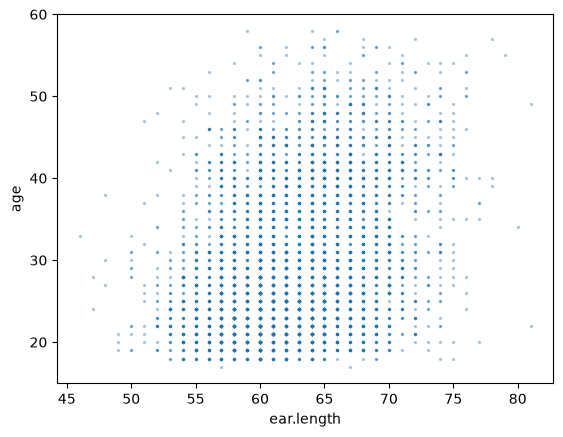

ear.length is most related to weight


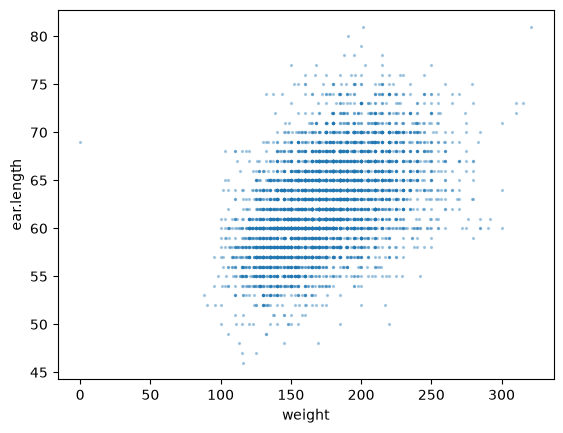

head.circumference is most related to head.height


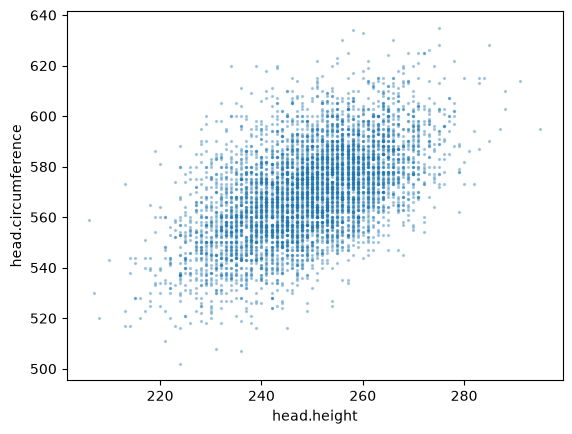

In [10]:
# Work on Data Exploration here
### Encode non-numerical features
print(ansur_df["gender"].unique())

# DISCLAIMER: i feel a bit... weird defining F and M as 1 and 0 (the binary... ) but just for this exercise  *cries
ansur_enc_df = ansur_df.copy()
ansur_enc_df["gender"] = ansur_enc_df["gender"].map({"F": 0, "M": 1})
print(ansur_enc_df["gender"].unique()) 


## 1. Print min, max, avg
for f in ansur_enc_df.columns:
  print(f)
  print("\tmin:", ansur_enc_df[f].min())
  print("\tmax:", ansur_enc_df[f].max())
  print("\tavg:", ansur_enc_df[f].mean())

### Normalize all data
ansur_scaled_df = StandardScaler().set_output(transform="pandas").fit_transform(ansur_enc_df)

## 2. Print Covariances
for feat in ["age", "ear.length", "head.circumference"]:
  print(feat)
  print(ansur_scaled_df.cov()[feat])
  print()

## 3. Plot features most correlated to age, ear length and head circumference
for feat in ["age", "ear.length", "head.circumference"]:
  covs = ansur_scaled_df.cov()[feat].drop(feat).abs().sort_values(ascending=False)
  best = covs.index[0]
  print(feat, "is most related to", best)

  plt.scatter(ansur_enc_df[best], ansur_enc_df[feat], s=2, alpha=0.3)
  plt.xlabel(best)
  plt.ylabel(feat)
  plt.show()

In [ ]:
#head circumference + head height, but head height--> stature (overall body height), with head circumference ranking lower.
# hmmm... i need to think 
covs_ear = ansur_scaled_df.cov()["ear.length"].drop("ear.length").abs().sort_values(ascending=False)
print(list(covs_ear.index).index("age") + 1)   # age's rank among ear.length's matches

covs_head = ansur_scaled_df.cov()["head.height"].drop("head.height").abs().sort_values(ascending=False)
print(covs_head.index[0])   

14
stature


In [14]:
print(ansur_scaled_df.cov()["weight"].drop("weight").abs().sort_values(ascending=False).index[0])

hand.breadth


### Interpretation

<span style="color:hotpink;">
Does anything stand out about these graphs? Or the correlations?<br>
Are correlations symmetric? Does the feature most correlated to ear length also have ear length as its most correlated pair?
</span>

<span style="color:hotpink;">

**Does anything stand out?**

- Age has a very weak relationship with every feature. Its top match is ear length, but the scatter plot is a shapeless cloud with maybe a faint upward tilt. When all the correlations are small, the “most related” feature is just the biggest of a small group, so it doesn’t mean much.
- Ear length vs. weight shows an ok positive trend.
- Head circumference vs. head height is the clearest relationship of the three, with a moderate positive trend that is visibly tighter than the others.
- Body size--> Several of the top matches (weight, stature) are overall body-size measurements, which suggests that many of these features move together with body size.

 **Are correlations symmetric?**

For any single pair, yes. The covariance of age with ear length is the same number as ear length with age, but the “most correlated feature” is not symmetric, because each feature has its own ranking/hierarchy.

 **Does the feature most correlated to ear length also have ear length as its most correlated pair?**

No. Ear length’s top match is weight, but weight’s top match is hand breadth. The same thing happens with age. Its top match is ear length, but age ranks only 14th on ear length’s list, because ear length relates much more strongly to other features. Head circumference and head height is another example, with head circumference’s top match is head height, but head height’s top match is stature. A feature with many strong partners (like body-size measurements) can be the best match for others without matching them back.

 **Limitations**

As the disclaimer at the start of this notebook, this dataset only describes U.S. Army personnel, so none of these relationships should be generalized to people overall.


</span>

### Regression

Now, we want to create a regression model to predict `head.circumference` from the data.

From our [Week 07](https://github.com/PSAM-5020-2026F-A/WK07) notebook, we can create a regression model by following these steps:

1. Load dataset (done! 🎉)
2. Encode label features as numbers (done! ⚡️)
3. Normalize the data (done! 🍾)
4. Separate the outcome variable and the input features
5. Create a regression model using all features
6. Run model on training data and measure error
7. Plot predictions and interpret results
8. Run model on test data, measure error, plot predictions, interpret results

13.910571985204236


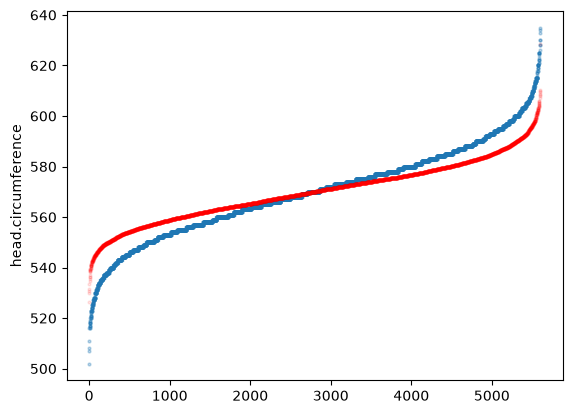

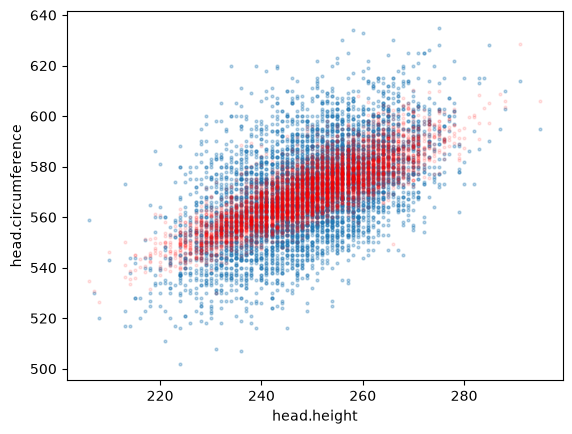

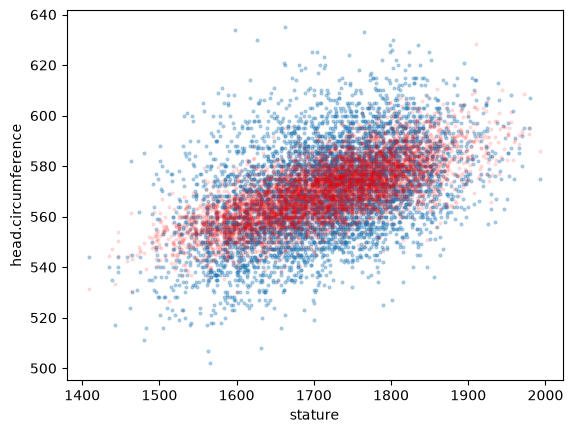

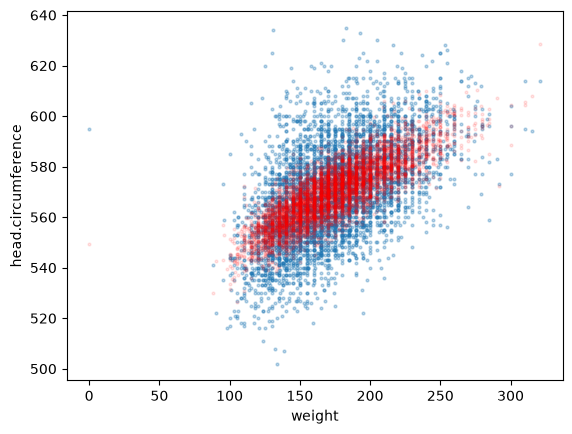

In [ ]:
# Work on Regression Model here
## Separate outcome variable and input features
outcome = ansur_enc_df[["head.circumference"]]
features = ansur_scaled_df.drop(columns=["head.circumference"])

## Create a regression model
head_reg_model = LinearRegression().fit(features, outcome)

## Measure error on training data
predicted_head_model = head_reg_model.predict(features)
print(regression_error(outcome, predicted_head_model))

## Plot predictions + interpret results
# sorted original vs. sorted predicted values
plt.plot(sorted(outcome["head.circumference"]), marker='o', linestyle='', alpha=0.3, markersize=2)
plt.plot(sorted(predicted_head_model), color='r', marker='o', linestyle='', alpha=0.1, markersize=2)
plt.ylabel("head.circumference")
plt.show()

# predictions vs.  individual features
for feat in ["head.height", "stature", "weight"]:
  plt.plot(ansur_enc_df[feat], outcome, marker='o', linestyle='', alpha=0.3, markersize=2)
  plt.plot(ansur_enc_df[feat], predicted_head_model, color='r', marker='o', linestyle='', alpha=0.1, markersize=2)
  plt.xlabel(feat)
  plt.ylabel("head.circumference")
  plt.show()

In [18]:
ansur_scaler = StandardScaler().set_output(transform="pandas")
ansur_scaled_df = ansur_scaler.fit_transform(ansur_enc_df)

In [23]:
## Load Test Data
ANSUR_TEST_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur-test.json"

ansur_test_data = object_from_json_url(ANSUR_TEST_FILE)
ansur_test_df = pd.json_normalize(ansur_test_data)

ansur_test_encoded_df = ansur_test_df.copy()
ansur_test_encoded_df["gender"] = ansur_test_encoded_df["gender"].map({"F": 0, "M": 1})

ansur_test_scaled_df = ansur_scaler.transform(ansur_test_encoded_df)

# checking
print(list(ansur_test_encoded_df.columns) == list(ansur_enc_df.columns))

# test error
test_outcome = ansur_test_encoded_df[["head.circumference"]]
test_features = ansur_test_scaled_df.drop(columns=["head.circumference"])

predicted_head_test = head_reg_model.predict(test_features)
print(regression_error(test_outcome, predicted_head_test))

True
14.4732380584235


train error: 13.910571985204236
test error: 14.4732380584235


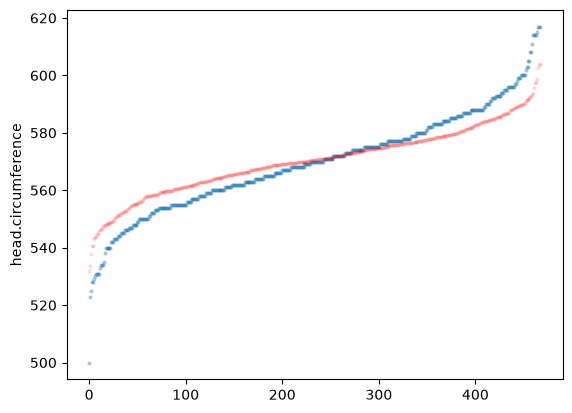

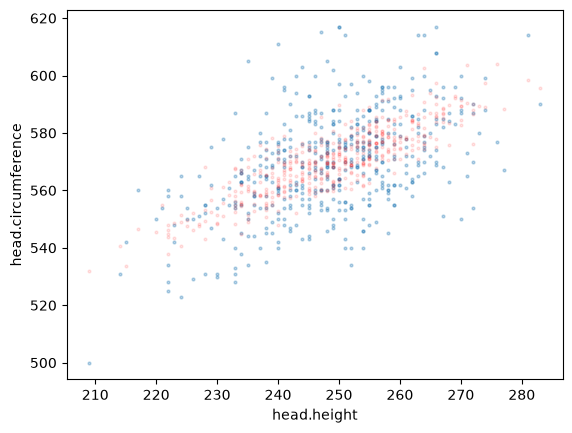

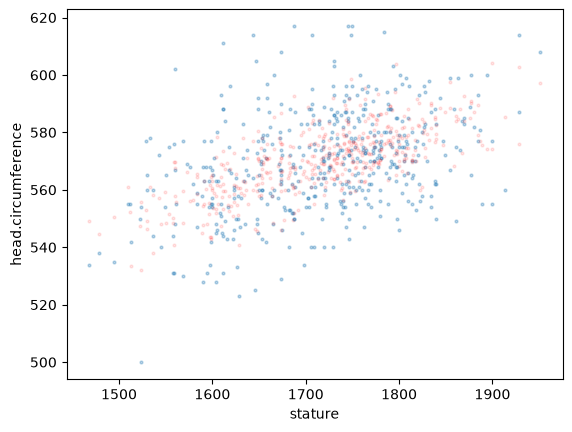

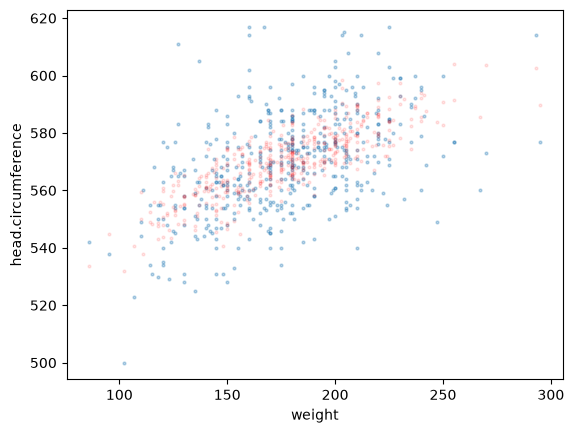

In [24]:
## Run model on test data
test_outcome = ansur_test_encoded_df[["head.circumference"]]
test_features = ansur_test_scaled_df.drop(columns=["head.circumference"])

predicted_head_test = head_reg_model.predict(test_features)

## Measure error on test data
print("train error:", regression_error(outcome, predicted_head_model))
print("test error:", regression_error(test_outcome, predicted_head_test))

## Plot predictions and interpret results
# sorted original vs. sorted predicted values
plt.plot(sorted(test_outcome["head.circumference"]), marker='o', linestyle='', alpha=0.3, markersize=2)
plt.plot(sorted(predicted_head_test), color='r', marker='o', linestyle='', alpha=0.1, markersize=2)
plt.ylabel("head.circumference")
plt.show()

# predictions vs. individual features
for feat in ["head.height", "stature", "weight"]:
  plt.plot(ansur_test_encoded_df[feat], test_outcome, marker='o', linestyle='', alpha=0.3, markersize=2)
  plt.plot(ansur_test_encoded_df[feat], predicted_head_test, color='r', marker='o', linestyle='', alpha=0.1, markersize=2)
  plt.xlabel(feat)
  plt.ylabel("head.circumference")
  plt.show()

In [25]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False).set_output(transform="pandas")
features_poly = poly.fit_transform(features)
test_features_poly = poly.transform(test_features)

poly_model = LinearRegression().fit(features_poly, outcome)
print("train error:", regression_error(outcome, poly_model.predict(features_poly)))
print("test error:", regression_error(test_outcome, poly_model.predict(test_features_poly)))

train error: 13.490438932300012
test error: 14.444534130968666


### Interpretation

<span style="color:hotpink;">
How well does your model perform?<br>
How could you improve it?<br>
Are there ranges of circumferences that don't get predicted well?
</span>

<span style="color:hotpink;"> ill get to this</span>